In [9]:
from langgraph.graph import StateGraph , START , END

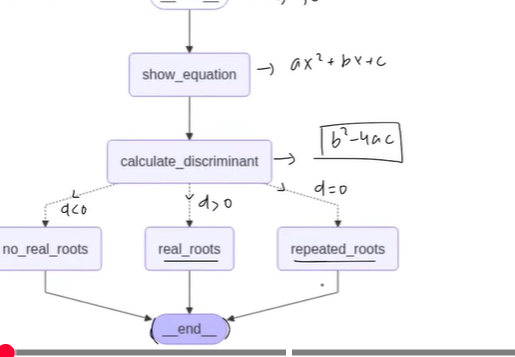

In [10]:
from typing import TypedDict
class EqnState(TypedDict):
    a_coefficient : float
    b_coefficient : float
    y_intercept : float
    eqn : str
    disc : float
    result : str

In [11]:
def show_equation(state : EqnState) -> EqnState :
    
    equation = f'{state["a_coefficient"]}x2{state["b_coefficient"]}x{state["y_intercept"]}'

    state["eqn"] = equation

    return state

def calc_disc(state : EqnState) -> EqnState :

    disc = state["b_coefficient"]**2 - 4*(state["a_coefficient"]*state["y_intercept"])

    state["disc"] = disc

    return state

In [12]:
from typing import Literal
from cmath import sqrt


def real_roots(state : EqnState) -> EqnState:

    root1 = (-state['b_coefficient'] + state['y_intercept']**0.5)/(2*state['a_coefficient'])
    root2 = (-state['b_coefficient'] - state['y_intercept'])/(2*state['a_coefficient'])

    result = f'The roots are {root1} and {root2}'

    return {'result' : result} 


def repeated_roots(state : EqnState) -> EqnState:

    root = (-state['b_coefficient'])/(2*state['a_coefficient'])
  

    result = f'The root is {root} '

    return {'result' : result} 


def no_real_roots(state : EqnState) -> EqnState:



    result = f'No real roots' 

    return {'result' : result} 


def check_condition(state : EqnState) -> Literal["real_roots","no_real_roots","repeated_roots"]:

    if(state['disc'] > 0):
        return "real_roots"
    elif( state['disc'] == 0):
        return "repeated_roots"
    else:
        return "no_real_roots"

# we are telling the condition function to go to which node to go for each condition , thats why we are writing node name 
     





In [13]:
graph = StateGraph(EqnState)


graph.add_node('show_equation' , show_equation)
graph.add_node('calc_disc' , calc_disc)
graph.add_node('real_roots' , real_roots)
graph.add_node('no_real_roots' , no_real_roots)
graph.add_node('repeated_roots' , repeated_roots)

graph.add_edge(START , 'show_equation')
graph.add_edge('show_equation' , 'calc_disc')
graph.add_conditional_edges('calc_disc' , check_condition)
# from calc_disc NODE , we need to decide which node to go to , the check_conditon decides that
graph.add_edge('real_roots' , END)
graph.add_edge('no_real_roots' , END)
graph.add_edge('repeated_roots' , END)

In [14]:
workflow = graph.compile()

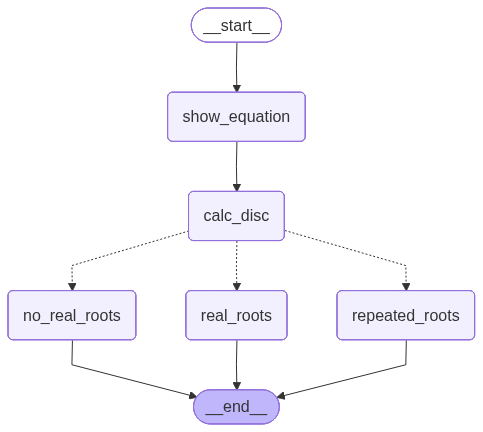

In [15]:
workflow

In [16]:
initial_state = {
    'a_coefficient' : 4,
    'b_coefficient' : -5,
    'y_intercept' : -4
}

workflow.invoke(initial_state)

{'a_coefficient': 4,
 'b_coefficient': -5,
 'y_intercept': -4,
 'eqn': '4x2-5x-4',
 'disc': 89,
 'result': 'The roots are (0.625+0.25j) and 1.125'}